# Glycoproteomics analysis pipeline (anonymized demonstration)

This notebook is generated from [`python/glycoproteomics_pipeline.py`](../python/glycoproteomics_pipeline.py)
and contains **26 glycoproteomics figures** computed on **simulated, fully anonymous data**:

* samples are **Sample A** (reference) to **Sample D**
* proteins are `Protein_0001` …, glycosites are `Protein_0001-N123` (N-linked) or `-S/T45` (O-linked)
* peptide sequences are random strings carrying an N-X-S/T sequon or S/T site

No real gene, protein, sample or patient identifiers are used anywhere.
Run all cells to reproduce the outputs; figures display inline (the `.py` script writes PNG/PDF files).

## Setup

In [1]:
%matplotlib inline
from __future__ import annotations

import string
import sys
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from scipy.cluster.hierarchy import leaves_list, linkage

IN_NOTEBOOK = "ipykernel" in sys.modules or "_FORCE_NOTEBOOK" in globals()
try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:                                   # notebook: cwd is notebooks/
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures" / "python"
DATA_DIR = ROOT / "data"
SAVE_FILES = not IN_NOTEBOOK                        # notebooks display inline only
if SAVE_FILES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    DATA_DIR.mkdir(parents=True, exist_ok=True)

SEED = 7
FDR_T, FC_T, DELTA_T = 0.05, 1.0, 1.0
MIN_VALID = 0.70

# Palette (validated): reference = neutral gray; samples & glycan classes fixed order
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
NS, UP, DOWN = "#c3c2b7", "#e34948", "#2a78d6"
SAMPLE_COLORS = ["#52514e", "#2a78d6", "#1baf7a", "#4a3aa7"]
CLASSES = ["High-mannose", "Paucimannose", "Hybrid", "Complex", "Fucosylated",
           "Sialylated", "Sialyl+Fucosylated", "O-glycan"]
CLASS_COLORS = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7",
                                  "#eda100", "#e34948", "#008300", "#e87ba4"]))
SITE_TYPE_COLORS = {"N": "#2a78d6", "O": "#e87ba4"}
DIVERGING = LinearSegmentedColormap.from_list(
    "div", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#8a2323"], N=256)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "seq", ["#b5d3f7", "#6da7ec", "#2a78d6", "#184f95"], N=256)
MM = 1 / 25.4
W1, W15, W2 = 89 * MM, 130 * MM, 183 * MM

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.titleweight": "bold", "axes.labelsize": 7,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5,
    "axes.edgecolor": MUTED, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "grid.color": GRID, "grid.linewidth": 0.5, "legend.frameon": False,
    "figure.facecolor": "white", "figure.constrained_layout.use": True,
    "figure.max_open_warning": 0, "savefig.dpi": 300, "savefig.bbox": "tight",
    "pdf.fonttype": 42, "svg.fonttype": "none",
})

FIGURES: list[tuple[str, plt.Figure]] = []


def save(fig, name):
    """Script: write PNG (and queue for the PDF). Notebook: figure displays inline."""
    if SAVE_FILES:
        fig.savefig(FIG_DIR / f"{name}.png")
        FIGURES.append((name, fig))
        print(f"  saved {name}.png")


def class_legend(ax, classes=CLASSES, **kw):
    ax.legend([Patch(color=CLASS_COLORS[c]) for c in classes], classes, **kw)

## Simulated anonymous glycoproteomics experiment

In [2]:
AA = list("ACDEFGHIKLMNQRSTVWY")                    # sequon X position excludes proline


def composition_class(hn, hx, f, s, kind):
    if kind == "O":
        return "O-glycan"
    if hn == 2:
        return "High-mannose" if hx >= 5 else "Paucimannose"
    if hn == 3 and hx >= 5:
        return "Hybrid"
    if f and s:
        return "Sialyl+Fucosylated"
    if s:
        return "Sialylated"
    if f:
        return "Fucosylated"
    return "Complex"


def composition_name(hn, hx, f, s):
    parts = [("HexNAc", hn), ("Hex", hx), ("Fuc", f), ("NeuAc", s)]
    return "".join(f"{k}({v})" for k, v in parts if v)


def glycan_library():
    n_lib = [(2, h, 0, 0) for h in range(5, 10)]
    n_lib += [(2, 3, 0, 0), (2, 3, 1, 0), (2, 4, 0, 0)]
    n_lib += [(3, 6, 0, 0), (3, 5, 0, 0), (3, 6, 1, 0), (3, 6, 0, 1)]
    for hn, hx in [(3, 4), (4, 4), (4, 5), (5, 6), (6, 7)]:
        for f in range(0, 3 if hn >= 5 else 2):
            for s in range(0, hn - 1):
                n_lib.append((hn, hx, f, s))
    o_lib = [(1, 0, 0, 0), (1, 0, 0, 1), (1, 1, 0, 0), (1, 1, 0, 1), (1, 1, 0, 2),
             (2, 2, 0, 0), (2, 2, 0, 1), (2, 2, 0, 2), (2, 2, 1, 1)]
    return n_lib, o_lib


def simulate(n_prot=350, n_samples=4, n_reps=4, seed=SEED):
    rng = np.random.default_rng(seed)
    samples = [f"Sample {string.ascii_uppercase[i]}" for i in range(n_samples)]
    n_lib, o_lib = glycan_library()
    prot_ids = [f"Protein_{i:04d}" for i in range(1, n_prot + 1)]
    length = rng.integers(250, 1600, n_prot)
    p_base = rng.normal(24, 1.8, n_prot)
    p_eff = np.zeros((n_prot, n_samples))
    for s in range(1, n_samples):
        hit = rng.random(n_prot) < 0.10
        p_eff[hit, s] = rng.choice([-1, 1], hit.sum()) * rng.normal(1.3, 0.4, hit.sum())

    rows, base_vals, site_rows = [], [], []
    for p in range(n_prot):
        n_n = min(1 + rng.geometric(0.45) - 1, 8)
        n_o = rng.integers(1, 4) if rng.random() < 0.30 else 0
        pos = np.sort(rng.choice(np.arange(20, length[p] - 20), n_n + n_o, replace=False))
        kinds = rng.permutation(["N"] * n_n + ["O"] * n_o)
        for site_pos, kind in zip(pos, kinds):
            left = "".join(rng.choice(AA, rng.integers(2, 7)))
            right = "".join(rng.choice(AA, rng.integers(2, 8))) + rng.choice(["K", "R"])
            if kind == "N":
                x_res, st = rng.choice(AA), rng.choice(["S", "T"], p=[0.4, 0.6])
                pep, site_lab = left + "N" + x_res + st + right, f"N{site_pos}"
                m, sp, fp = rng.beta(1.2, 2.2), rng.beta(2, 2), rng.beta(1.5, 1.5)
                lib = n_lib
                w = []
                for hn, hx, f, s in lib:
                    c = composition_class(hn, hx, f, s, "N")
                    if c == "High-mannose":
                        wi = 3 * m
                    elif c == "Paucimannose":
                        wi = 0.25
                    elif c == "Hybrid":
                        wi = 0.5
                    else:
                        wi = (1 - m) * (sp if s else 1 - sp) * 2 * (fp if f else 1 - fp)
                    w.append(wi + 1e-3)
                k = rng.integers(2, 14)
            else:
                x_res, st = "", ""
                res = rng.choice(["S", "T"], p=[0.4, 0.6])
                pep, site_lab = left + res + right, f"{res}{site_pos}"
                lib, w, k = o_lib, [0.5, 0.6, 1, 1, 0.8, 0.6, 0.6, 0.4, 0.3], rng.integers(1, 6)
            w = np.array(w) / np.sum(w)
            chosen = rng.choice(len(lib), min(k, len(lib)), replace=False, p=w)
            share = rng.dirichlet(np.full(chosen.size, 0.8))
            site_id = f"{prot_ids[p]}-{site_lab}"
            site_rows.append({"Site": site_id, "Protein": prot_ids[p], "Type": kind,
                              "Position": site_pos, "Length": length[p], "Sequon_X": x_res,
                              "Sequon_ST": st})
            for g, sh in zip(chosen, share):
                hn, hx, f, s = lib[g]
                rows.append({"Protein": prot_ids[p], "Site": site_id, "Type": kind,
                             "Peptide": pep, "Composition": composition_name(hn, hx, f, s),
                             "HexNAc": hn, "Hex": hx, "Fuc": f, "NeuAc": s,
                             "Class": composition_class(hn, hx, f, s, kind), "p": p})
                base_vals.append(p_base[p] + 0.9 * np.log2(sh * chosen.size) - 1
                                 + rng.normal(0, 0.7))
    gp = pd.DataFrame(rows)
    gp.index = [f"GP_{i:05d}" for i in range(1, len(gp) + 1)]
    base = np.array(base_vals)

    # Glycan-specific effects (arbitrary, for demonstration only)
    eff = np.zeros((len(gp), n_samples))
    mult = lambda: rng.normal(1.0, 0.3, len(gp)) * (rng.random(len(gp)) < 0.75)
    eff[:, 1] += 1.3 * (gp.Fuc.values > 0) * (gp.Type.values == "N") * mult()
    eff[:, 2] += (1.4 * (gp.NeuAc.values >= 2) - 0.7 * (gp.Class.values == "Complex")
                  + 0.6 * (gp.HexNAc.values >= 5)) * mult()
    eff[:, 3] += (-1.5 * (gp.Class.values == "High-mannose")
                  + 1.8 * ((gp.Type.values == "O") & (gp.Hex.values == 0))) * mult()
    for s in range(1, n_samples):
        rnd = rng.random(len(gp)) < 0.02
        eff[rnd, s] += rng.choice([-1, 1], rnd.sum()) * rng.normal(1.5, 0.3, rnd.sum())

    cols, gdat, pdat = [], [], []
    for s in range(n_samples):
        for r in range(1, n_reps + 1):
            off = rng.normal(0, 0.2)
            cols.append(f"{samples[s]}_R{r}")
            gdat.append(base + eff[:, s] + p_eff[gp.p.values, s] + rng.normal(0, 0.4, len(gp)) + off)
            pdat.append(p_base + p_eff[:, s] + rng.normal(0, 0.25, n_prot) + off)
    graw = pd.DataFrame(np.column_stack(gdat), index=gp.index, columns=cols)
    low = graw.values < np.quantile(graw.values, 0.08)
    graw = graw.mask((low & (rng.random(graw.shape) < 0.6)) | (rng.random(graw.shape) < 0.02))
    praw = pd.DataFrame(np.column_stack(pdat), index=prot_ids, columns=cols)
    return gp.drop(columns="p"), graw, praw, pd.DataFrame(site_rows).set_index("Site"), samples


def design_of(cols):
    return pd.Series([c.rsplit("_R", 1)[0] for c in cols], index=cols)


def preprocess(raw, seed=SEED):
    rng = np.random.default_rng(seed)
    d = design_of(raw.columns)
    valid = raw.notna().T.groupby(d).mean().T
    x = raw.loc[(valid >= MIN_VALID).any(axis=1)]
    med = x.median()
    norm = x - med + med.mean()
    imp = norm.isna()
    out = norm.copy()
    for c in out.columns:
        mu, sd = norm[c].mean() - 1.8 * norm[c].std(), 0.3 * norm[c].std()
        out.loc[imp[c], c] = rng.normal(mu, sd, imp[c].sum())
    return out, norm, imp


def bh(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    q = np.minimum.accumulate((p[o] * p.size / np.arange(1, p.size + 1))[::-1])[::-1]
    out = np.empty(p.size)
    out[o] = np.clip(q, 0, 1)
    return out


def welch(x, samples):
    d = design_of(x.columns)
    ref = x.loc[:, d == samples[0]]
    res = []
    for s in samples[1:]:
        t_ = x.loc[:, d == s]
        t, p = stats.ttest_ind(t_, ref, axis=1, equal_var=False)
        df = pd.DataFrame({"ID": x.index, "Sample": s,
                           "log2FC": t_.mean(axis=1).values - ref.mean(axis=1).values,
                           "pvalue": p, "adj_pvalue": bh(p)})
        res.append(df)
    return pd.concat(res, ignore_index=True)


GP_ALL, GRAW, PRAW, SITES, SAMPLES = simulate()
X, NORM, IMP = preprocess(GRAW)
GP = GP_ALL.loc[X.index]
XP, _, _ = preprocess(PRAW)
DESIGN = design_of(X.columns)
OTHERS = SAMPLES[1:]
SCOL = dict(zip(SAMPLES, SAMPLE_COLORS))
SHORT = [c.replace("Sample ", "").replace("_", "-") for c in X.columns]

DE = welch(X, SAMPLES).rename(columns={"ID": "GP"})
DEP = welch(XP, SAMPLES).rename(columns={"ID": "Protein", "log2FC": "protein_log2FC",
                                         "adj_pvalue": "protein_adj_p"})
DE = DE.merge(GP[["Protein", "Site", "Type", "Composition", "Class", "HexNAc", "Hex", "Fuc",
                  "NeuAc"]], left_on="GP", right_index=True)
DE = DE.merge(DEP[["Protein", "Sample", "protein_log2FC", "protein_adj_p"]],
              on=["Protein", "Sample"], how="left")
DE["glyco_delta"] = DE.log2FC - DE.protein_log2FC
DE["neglog10_adjp"] = -np.log10(DE.adj_pvalue.clip(lower=1e-300))
DE["call"] = np.select([(DE.adj_pvalue < FDR_T) & (DE.log2FC > FC_T),
                        (DE.adj_pvalue < FDR_T) & (DE.log2FC < -FC_T)], ["up", "down"], "ns")
DE["decoupled"] = (DE.adj_pvalue < FDR_T) & (DE.glyco_delta.abs() > DELTA_T)
LIN = 2 ** X
print(f"{len(GP_ALL)} glycopeptides simulated, {len(GP)} retained | "
      f"{GP.Site.nunique()} glycosites on {GP.Protein.nunique()} proteins | "
      f"{(GP.Type == 'N').sum()} N- / {(GP.Type == 'O').sum()} O-glycopeptides")


def sample_mean_share(mask=None, by="Class"):
    """Per-sample mean (over replicates) share of summed intensity by a column."""
    sub = LIN if mask is None else LIN.loc[mask]
    grp = GP.loc[sub.index, by]
    per_rep = sub.groupby(grp).sum() / sub.sum()
    return per_rep.T.groupby(DESIGN).mean().T[SAMPLES] * 100

6511 glycopeptides simulated, 6374 retained | 1008 glycosites on 350 proteins | 5774 N- / 600 O-glycopeptides


## 01 Glycopeptide identifications per replicate

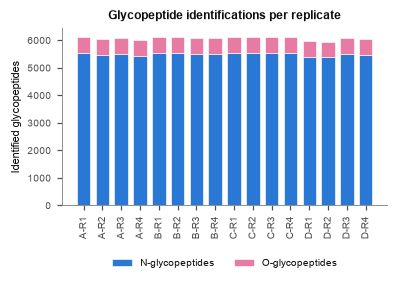

In [3]:
fig, ax = plt.subplots(figsize=(W1, 62 * MM))
ids = GRAW.notna().groupby(GP_ALL.Type).sum()
xs = np.arange(len(SHORT))
ax.bar(xs, ids.loc["N"], color=SITE_TYPE_COLORS["N"], width=0.72, label="N-glycopeptides",
       edgecolor="white", lw=0.4)
ax.bar(xs, ids.loc["O"], bottom=ids.loc["N"], color=SITE_TYPE_COLORS["O"], width=0.72,
       label="O-glycopeptides", edgecolor="white", lw=0.4)
ax.set_xticks(xs, SHORT, rotation=90)
ax.set_ylabel("Identified glycopeptides")
ax.set_title("Glycopeptide identifications per replicate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
save(fig, "01_glycopeptide_identifications")

## 02 Glycan-class composition per sample

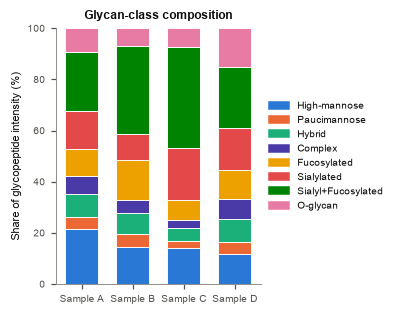

In [4]:
fig, ax = plt.subplots(figsize=(W1, 70 * MM))
comp = sample_mean_share().reindex(CLASSES).fillna(0)
bottom = np.zeros(len(SAMPLES))
for c in CLASSES:
    ax.bar(SAMPLES, comp.loc[c], bottom=bottom, color=CLASS_COLORS[c], width=0.65,
           edgecolor="white", lw=0.6)
    bottom += comp.loc[c].values
ax.set_ylabel("Share of glycopeptide intensity (%)")
ax.set_ylim(0, 100)
ax.set_title("Glycan-class composition")
class_legend(ax, loc="center left", bbox_to_anchor=(1.0, 0.5))
save(fig, "02_glycan_class_composition")

## 03 Glycosites per protein

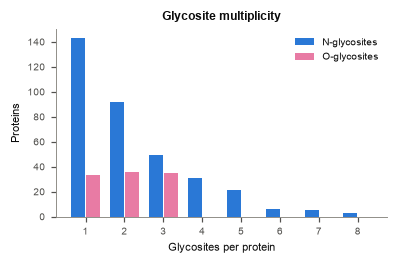

In [5]:
fig, ax = plt.subplots(figsize=(W1, 58 * MM))
kept_sites = SITES.loc[GP.Site.unique()]
cnt = kept_sites.groupby(["Protein", "Type"]).size().unstack(fill_value=0)
mx = int(cnt.values.max())
bins = np.arange(1, mx + 1)
for i, t in enumerate(["N", "O"]):
    v = cnt[t][cnt[t] > 0].value_counts().reindex(bins, fill_value=0)
    ax.bar(bins + (i - 0.5) * 0.38, v.values, width=0.36, color=SITE_TYPE_COLORS[t],
           label=f"{t}-glycosites")
ax.set_xticks(bins)
ax.set_xlabel("Glycosites per protein")
ax.set_ylabel("Proteins")
ax.set_title("Glycosite multiplicity")
ax.legend()
save(fig, "03_glycosites_per_protein")

## 04 Glycoforms per site (microheterogeneity)

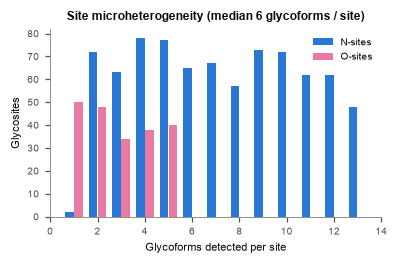

In [6]:
fig, ax = plt.subplots(figsize=(W1, 58 * MM))
per_site = GP.groupby(["Site", "Type"]).size().reset_index(name="n")
mx = per_site.n.max()
for i, t in enumerate(["N", "O"]):
    v = per_site[per_site.Type == t].n.value_counts().reindex(range(1, mx + 1), fill_value=0)
    ax.bar(np.arange(1, mx + 1) + (i - 0.5) * 0.38, v.values, width=0.36,
           color=SITE_TYPE_COLORS[t], label=f"{t}-sites")
ax.set_xlabel("Glycoforms detected per site")
ax.set_ylabel("Glycosites")
ax.set_title(f"Site microheterogeneity (median {per_site.n.median():.0f} glycoforms / site)")
ax.legend()
save(fig, "04_glycoforms_per_site")

## 05 N-glycan composition space

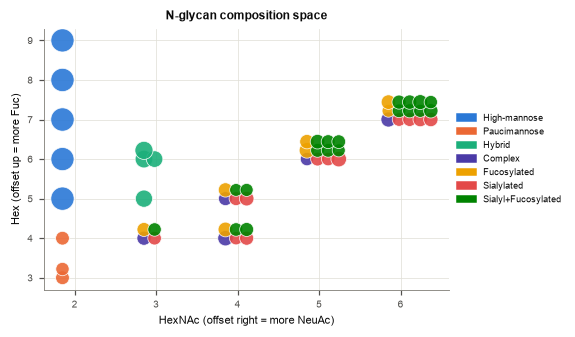

In [7]:
fig, ax = plt.subplots(figsize=(W15, 75 * MM))
nc = GP[GP.Type == "N"].groupby(["HexNAc", "Hex", "Fuc", "NeuAc", "Class"]).size().reset_index(name="n")
xj = nc.HexNAc + 0.13 * nc.NeuAc - 0.15
yj = nc.Hex + 0.22 * nc.Fuc
ax.scatter(xj, yj, s=nc.n * 0.9 + 6, c=nc.Class.map(CLASS_COLORS), edgecolors="white", lw=0.5,
           alpha=0.9, zorder=3)
ax.set_xlabel("HexNAc (offset right = more NeuAc)")
ax.set_ylabel("Hex (offset up = more Fuc)")
ax.set_xticks(range(2, 7))
ax.set_yticks(range(3, 10))
ax.grid(True, zorder=0)
ax.set_title("N-glycan composition space")
class_legend(ax, CLASSES[:-1], loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=6)
save(fig, "05_nglycan_composition_space")

## 06 Sequon usage

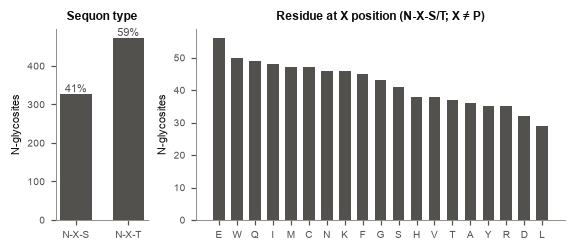

In [8]:
nsite = kept_sites[kept_sites.Type == "N"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W15, 55 * MM), gridspec_kw=dict(width_ratios=[1, 4]))
st = nsite.Sequon_ST.value_counts().reindex(["S", "T"])
a1.bar(["N-X-S", "N-X-T"], st.values, color=INK2, width=0.6)
for i, v in enumerate(st.values):
    a1.text(i, v, f"{100 * v / st.sum():.0f}%", ha="center", va="bottom", color=INK2)
a1.set_ylabel("N-glycosites")
a1.set_title("Sequon type")
xr = nsite.Sequon_X.value_counts()
a2.bar(xr.index, xr.values, color=INK2, width=0.65)
a2.set_title("Residue at X position (N-X-S/T; X ≠ P)")
a2.set_ylabel("N-glycosites")
save(fig, "06_sequon_usage")

## 07 Glycosite position along the protein

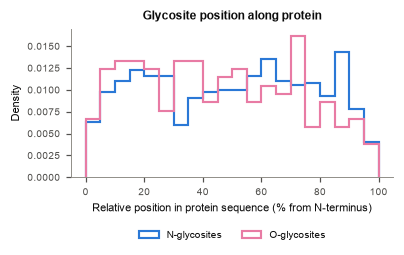

In [9]:
fig, ax = plt.subplots(figsize=(W1, 55 * MM))
rel = kept_sites.Position / kept_sites.Length * 100
for t in ["N", "O"]:
    ax.hist(rel[kept_sites.Type == t], bins=np.linspace(0, 100, 21), histtype="step", lw=1.4,
            color=SITE_TYPE_COLORS[t], label=f"{t}-glycosites", density=True)
ax.set_xlabel("Relative position in protein sequence (% from N-terminus)")
ax.set_ylabel("Density")
ax.set_title("Glycosite position along protein")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
save(fig, "07_glycosite_position")

## 08 Glycopeptide intensity distributions

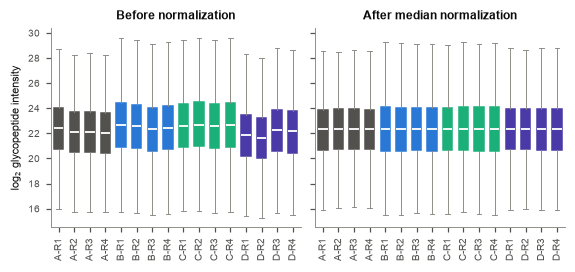

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(W15, 60 * MM), sharey=True)
for ax, data, ttl in [(axes[0], GRAW, "Before normalization"), (axes[1], NORM, "After median normalization")]:
    bp = ax.boxplot([data[c].dropna() for c in data.columns], widths=0.6, patch_artist=True,
                    showfliers=False, medianprops=dict(color="white", lw=1.2),
                    whiskerprops=dict(color=MUTED, lw=0.6), capprops=dict(color=MUTED, lw=0.6))
    for patch, c in zip(bp["boxes"], data.columns):
        col = SCOL[DESIGN[c]]
        patch.set(facecolor=col, edgecolor=col)
    ax.set_xticks(range(1, len(SHORT) + 1), SHORT, rotation=90)
    ax.set_title(ttl)
axes[0].set_ylabel("log$_2$ glycopeptide intensity")
save(fig, "08_intensity_boxplots")

## 09 Replicate correlation

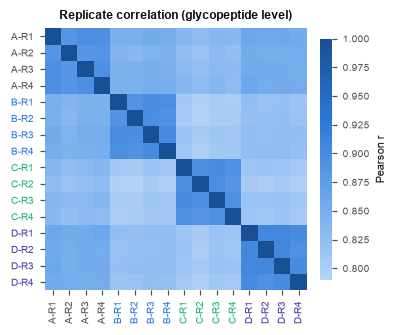

In [11]:
fig, ax = plt.subplots(figsize=(W1, 82 * MM))
R = np.corrcoef(X.T.values)
im = ax.imshow(R, cmap=SEQUENTIAL, vmin=np.floor(R.min() * 100) / 100, vmax=1)
ax.set_xticks(range(len(SHORT)), SHORT, rotation=90)
ax.set_yticks(range(len(SHORT)), SHORT)
for lab in ax.get_xticklabels() + ax.get_yticklabels():
    lab.set_color(SCOL["Sample " + lab.get_text()[0]])
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046)
cb.set_label("Pearson r")
cb.outline.set_visible(False)
ax.set_title("Replicate correlation (glycopeptide level)")
save(fig, "09_replicate_correlation")

## 10 PCA

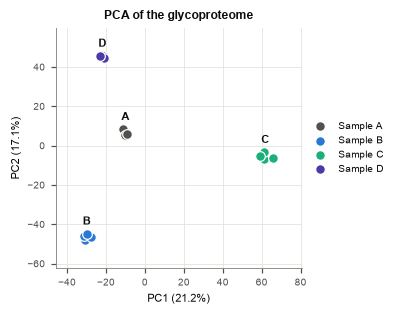

In [12]:
Xc = X.T.values - X.T.values.mean(axis=0)
U, S_, Vt = np.linalg.svd(Xc, full_matrices=False)
pcs, var = U * S_, S_ ** 2 / np.sum(S_ ** 2) * 100
fig, ax = plt.subplots(figsize=(W1, 70 * MM))
for s in SAMPLES:
    m = (DESIGN == s).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=40, c=SCOL[s], edgecolors="white", lw=0.8, label=s, zorder=3)
    ax.annotate(s[-1], (pcs[m, 0].mean(), pcs[m, 1].max()), xytext=(0, 6),
                textcoords="offset points", ha="center", fontweight="bold")
ax.set_xlabel(f"PC1 ({var[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({var[1]:.1f}%)")
ax.grid(True, zorder=0)
ax.margins(0.15)
ax.set_title("PCA of the glycoproteome")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
save(fig, "10_pca")

## 11 Glycopeptide volcano plots

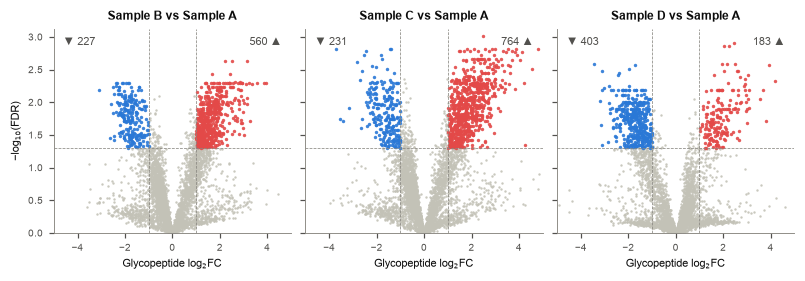

In [13]:
xl = np.ceil(DE.log2FC.abs().quantile(0.999) + 0.5)
yl = DE.neglog10_adjp.quantile(0.999) * 1.12
fig, axes = plt.subplots(1, 3, figsize=(W2, 62 * MM), sharey=True)
for ax, s in zip(axes, OTHERS):
    sub = DE[DE.Sample == s]
    for call, c, sz in [("ns", NS, 2.5), ("down", DOWN, 5), ("up", UP, 5)]:
        d = sub[sub.call == call]
        ax.scatter(d.log2FC, d.neglog10_adjp, s=sz, c=c, lw=0, alpha=0.9, rasterized=True)
    for v in (-FC_T, FC_T):
        ax.axvline(v, color=MUTED, ls="--", lw=0.5)
    ax.axhline(-np.log10(FDR_T), color=MUTED, ls="--", lw=0.5)
    ax.set_xlim(-xl, xl)
    ax.set_ylim(0, yl)
    ax.text(0.04, 0.96, f"▼ {(sub.call == 'down').sum()}", transform=ax.transAxes, va="top", color=INK2)
    ax.text(0.96, 0.96, f"{(sub.call == 'up').sum()} ▲", transform=ax.transAxes, va="top",
            ha="right", color=INK2)
    ax.set_title(f"{s} vs Sample A")
    ax.set_xlabel("Glycopeptide log$_2$FC")
axes[0].set_ylabel("−log$_{10}$(FDR)")
save(fig, "11_glycopeptide_volcano")

## 12 Glycopeptide vs protein fold change (decoupling)

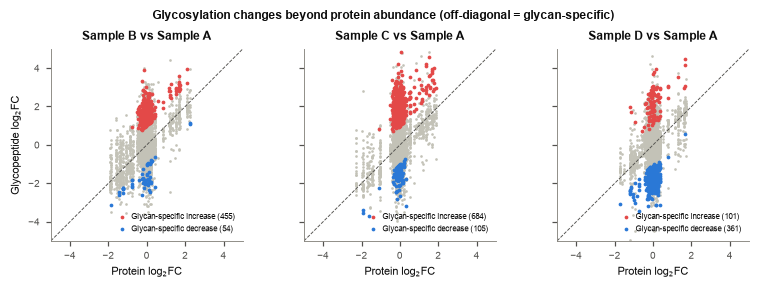

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(W2, 64 * MM), sharex=True, sharey=True)
lim = np.ceil(max(DE.log2FC.abs().quantile(0.999), DE.protein_log2FC.abs().quantile(0.999)))
for ax, s in zip(axes, OTHERS):
    sub = DE[(DE.Sample == s) & DE.protein_log2FC.notna()]
    base = sub[~sub.decoupled]
    ax.scatter(base.protein_log2FC, base.log2FC, s=3, c=NS, lw=0, rasterized=True)
    for sign, c, lab in [(1, UP, "Glycan-specific increase"), (-1, DOWN, "Glycan-specific decrease")]:
        d = sub[sub.decoupled & (np.sign(sub.glyco_delta) == sign)]
        ax.scatter(d.protein_log2FC, d.log2FC, s=6, c=c, lw=0, label=f"{lab} ({len(d)})")
    ax.plot([-lim, lim], [-lim, lim], color=INK2, lw=0.6, ls="--")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_title(f"{s} vs Sample A")
    ax.set_xlabel("Protein log$_2$FC")
    ax.legend(loc="lower right", fontsize=5.5, handletextpad=0.1)
axes[0].set_ylabel("Glycopeptide log$_2$FC")
fig.suptitle("Glycosylation changes beyond protein abundance (off-diagonal = glycan-specific)",
             fontweight="bold", fontsize=8)
save(fig, "12_glyco_vs_protein_fold_change")

## 13 log2FC by glycan class

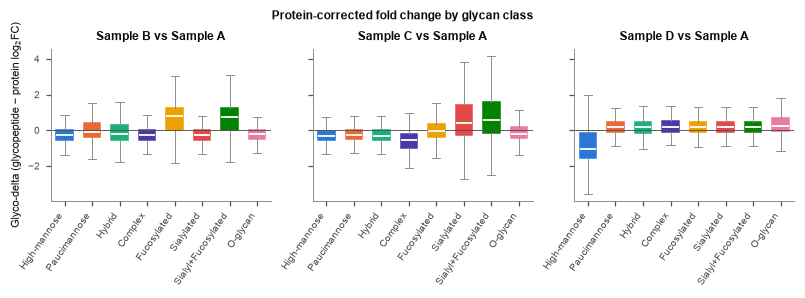

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(W2, 66 * MM), sharey=True)
for ax, s in zip(axes, OTHERS):
    sub = DE[DE.Sample == s]
    data = [sub.loc[sub.Class == c, "glyco_delta"].dropna() for c in CLASSES]
    bp = ax.boxplot(data, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops=dict(color="white", lw=1.2), whiskerprops=dict(color=MUTED, lw=0.6),
                    capprops=dict(color=MUTED, lw=0.6))
    for patch, c in zip(bp["boxes"], CLASSES):
        patch.set(facecolor=CLASS_COLORS[c], edgecolor=CLASS_COLORS[c])
    ax.axhline(0, color=INK2, lw=0.6)
    ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES, rotation=55, ha="right")
    ax.set_title(f"{s} vs Sample A")
axes[0].set_ylabel("Glyco-delta (glycopeptide − protein log$_2$FC)")
fig.suptitle("Protein-corrected fold change by glycan class", fontweight="bold", fontsize=8)
save(fig, "13_log2fc_by_glycan_class")

## 14 Significant changes by glycan class

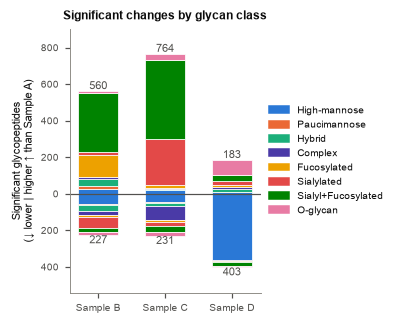

In [16]:
fig, ax = plt.subplots(figsize=(W1, 72 * MM))
for i, s in enumerate(OTHERS):
    sub = DE[DE.Sample == s]
    upc = sub[sub.call == "up"].Class.value_counts().reindex(CLASSES, fill_value=0)
    dnc = sub[sub.call == "down"].Class.value_counts().reindex(CLASSES, fill_value=0)
    bu = bd = 0
    for c in CLASSES:
        ax.bar(i, upc[c], bottom=bu, color=CLASS_COLORS[c], width=0.6, edgecolor="white", lw=0.5)
        ax.bar(i, -dnc[c], bottom=-bd, color=CLASS_COLORS[c], width=0.6, edgecolor="white", lw=0.5)
        bu += upc[c]
        bd += dnc[c]
    ax.text(i, bu, f"{bu}", ha="center", va="bottom", color=INK2)
    ax.text(i, -bd, f"{bd}", ha="center", va="top", color=INK2)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(len(OTHERS)), OTHERS)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{abs(int(v))}"))
ax.set_ylabel("Significant glycopeptides\n(↓ lower | higher ↑ than Sample A)")
ax.margins(y=0.12)
ax.set_title("Significant changes by glycan class")
class_legend(ax, loc="center left", bbox_to_anchor=(1.0, 0.5))
save(fig, "14_significant_changes_by_class")

## 15 Derived glycan traits

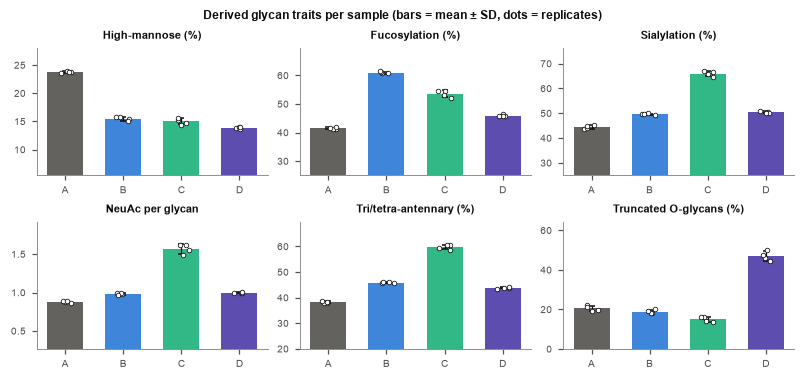

In [17]:
nmask = GP.Type == "N"
omask = GP.Type == "O"
ln, lo = LIN.loc[nmask], LIN.loc[omask]
gn = GP.loc[nmask]
TRAITS = pd.DataFrame({
    "High-mannose (%)": ln[gn.Class == "High-mannose"].sum() / ln.sum() * 100,
    "Paucimannose (%)": ln[gn.Class == "Paucimannose"].sum() / ln.sum() * 100,
    "Hybrid (%)": ln[gn.Class == "Hybrid"].sum() / ln.sum() * 100,
    "Fucosylation (%)": ln[gn.Fuc > 0].sum() / ln.sum() * 100,
    "Sialylation (%)": ln[gn.NeuAc > 0].sum() / ln.sum() * 100,
    "NeuAc per glycan": (ln.mul(gn.NeuAc, axis=0)).sum() / ln.sum(),
    "Tri/tetra-antennary (%)": ln[gn.HexNAc >= 5].sum() / ln.sum() * 100,
    "Truncated O-glycans (%)": lo[GP.loc[omask].Hex == 0].sum() / lo.sum() * 100,
}).T
show = ["High-mannose (%)", "Fucosylation (%)", "Sialylation (%)", "NeuAc per glycan",
        "Tri/tetra-antennary (%)", "Truncated O-glycans (%)"]
fig, axes = plt.subplots(2, 3, figsize=(W2, 85 * MM))
rng_j = np.random.default_rng(SEED)
for ax, tr in zip(axes.flat, show):
    for i, s in enumerate(SAMPLES):
        v = TRAITS.loc[tr, DESIGN == s].values
        ax.bar(i, v.mean(), color=SCOL[s], width=0.62, alpha=0.9)
        ax.errorbar(i, v.mean(), yerr=v.std(ddof=1), color=INK, lw=0.8, capsize=2)
        ax.scatter(i + rng_j.uniform(-0.13, 0.13, v.size), v, s=9, c="white", edgecolors=INK,
                   lw=0.5, zorder=3)
    ax.set_xticks(range(len(SAMPLES)), [s[-1] for s in SAMPLES])
    ax.set_title(tr, fontsize=7)
    lo_, hi_ = TRAITS.loc[tr].min(), TRAITS.loc[tr].max()
    ax.set_ylim(max(0, lo_ - (hi_ - lo_) * 0.8), hi_ + (hi_ - lo_) * 0.4)
fig.suptitle("Derived glycan traits per sample (bars = mean ± SD, dots = replicates)",
             fontweight="bold", fontsize=8)
save(fig, "15_derived_glycan_traits")

## 16 Derived-trait fold-change heatmap

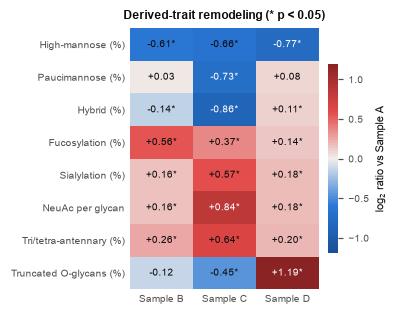

In [18]:
tmean = TRAITS.T.groupby(DESIGN).mean().T[SAMPLES]
tfc = np.log2(tmean[OTHERS].div(tmean[SAMPLES[0]], axis=0))
tp = pd.DataFrame({s: stats.ttest_ind(TRAITS.loc[:, DESIGN == s], TRAITS.loc[:, DESIGN == SAMPLES[0]],
                                      axis=1, equal_var=False)[1] for s in OTHERS}, index=TRAITS.index)
fig, ax = plt.subplots(figsize=(W1, 70 * MM))
lim = np.abs(tfc.values).max()
im = ax.imshow(tfc.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
for i in range(tfc.shape[0]):
    for j in range(tfc.shape[1]):
        star = "*" if tp.iloc[i, j] < 0.05 else ""
        v = tfc.iloc[i, j]
        ax.text(j, i, f"{v:+.2f}{star}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > lim * 0.6 else INK)
ax.set_xticks(range(len(OTHERS)), OTHERS)
ax.set_yticks(range(len(tfc)), tfc.index)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.05)
cb.set_label("log$_2$ ratio vs Sample A")
cb.outline.set_visible(False)
ax.set_title("Derived-trait remodeling (* p < 0.05)")
save(fig, "16_derived_trait_heatmap")

## 17 Clustered heatmap of top glycopeptides

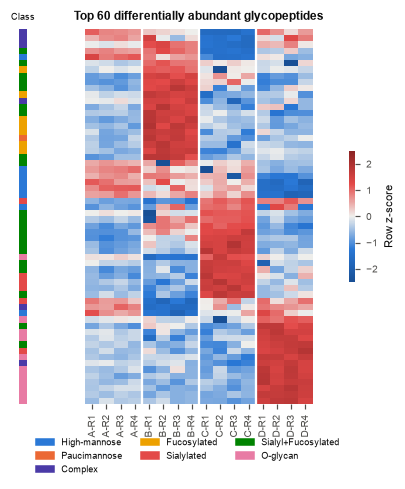

In [19]:
top = list(dict.fromkeys(DE[DE.call != "ns"].sort_values("adj_pvalue").groupby("Sample", sort=False)
                         .head(20).GP))
Z = X.loc[top]
Z = Z.sub(Z.mean(axis=1), axis=0).div(Z.std(axis=1, ddof=1), axis=0)
Z = Z.iloc[leaves_list(linkage(Z.values, "average", metric="correlation"))]
fig, (axc, ax) = plt.subplots(1, 2, figsize=(W1, 110 * MM), gridspec_kw=dict(width_ratios=[0.6, 16]))
cls = GP.loc[Z.index, "Class"]
axc.imshow(np.array([[mpl.colors.to_rgb(CLASS_COLORS[c])] for c in cls]), aspect="auto")
axc.set_xticks([])
axc.set_yticks([])
axc.set_title("Class", fontsize=6, fontweight="normal")
for sp in axc.spines.values():
    sp.set_visible(False)
im = ax.imshow(Z.values, aspect="auto", cmap=DIVERGING, vmin=-2.5, vmax=2.5, interpolation="nearest")
bounds = np.cumsum([(DESIGN == s).sum() for s in SAMPLES])
for b in bounds[:-1]:
    ax.axvline(b - 0.5, color="white", lw=1.5)
ax.set_xticks(range(len(SHORT)), SHORT, rotation=90)
ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.05, shrink=0.35)
cb.set_label("Row z-score")
cb.outline.set_visible(False)
ax.set_title(f"Top {len(Z)} differentially abundant glycopeptides")
class_legend(ax, sorted(set(cls), key=CLASSES.index), loc="upper center",
             bbox_to_anchor=(0.45, -0.07), ncol=3, fontsize=6)
save(fig, "17_top_glycopeptide_heatmap")

## 18 Site-specific glycoform profiles

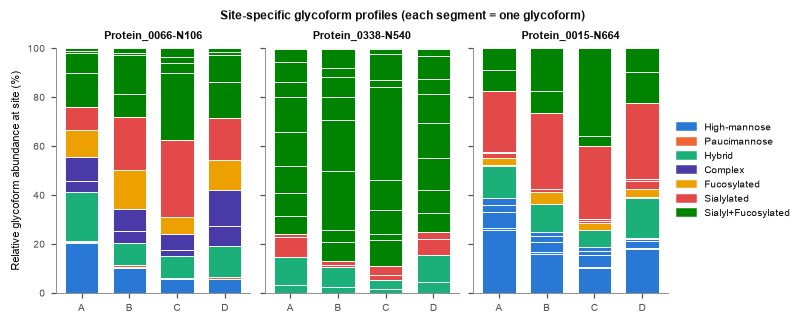

In [20]:
site_n = GP.groupby("Site").size()
cand = DE[DE.Site.isin(site_n[site_n >= 6].index) & (DE.Type == "N")]
top_sites = cand.groupby("Site").glyco_delta.apply(lambda v: v.abs().sum()).sort_values().index[-3:][::-1]
fig, axes = plt.subplots(1, 3, figsize=(W2, 72 * MM), sharey=True)
for ax, site in zip(axes, top_sites):
    gps = GP[GP.Site == site].copy()
    gps["order"] = gps.Class.map(CLASSES.index)
    gps = gps.sort_values(["order", "HexNAc", "Hex"])
    rel = LIN.loc[gps.index].T.groupby(DESIGN).mean().T[SAMPLES]
    rel = rel / rel.sum() * 100
    bottom = np.zeros(len(SAMPLES))
    for g in gps.index:
        ax.bar([s[-1] for s in SAMPLES], rel.loc[g], bottom=bottom, color=CLASS_COLORS[gps.Class[g]],
               width=0.7, edgecolor="white", lw=0.6)
        bottom += rel.loc[g].values
    ax.set_title(site, fontsize=7)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Relative glycoform abundance at site (%)")
class_legend(axes[-1], sorted(set(GP[GP.Site.isin(top_sites)].Class), key=CLASSES.index),
             loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.suptitle("Site-specific glycoform profiles (each segment = one glycoform)", fontweight="bold",
             fontsize=8)
save(fig, "18_site_glycoform_profiles")

## 19 UpSet overlap of changed glycopeptides

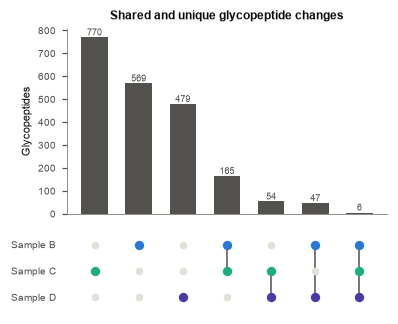

In [21]:
sets = {s: set(DE[(DE.Sample == s) & (DE.call != "ns")].GP) for s in OTHERS}
combos = []
for r in range(1, len(OTHERS) + 1):
    for cmb in combinations(OTHERS, r):
        inside = set.intersection(*(sets[s] for s in cmb))
        outside = set().union(*(sets[s] for s in OTHERS if s not in cmb))
        combos.append((cmb, len(inside - outside)))
combos = sorted([c for c in combos if c[1]], key=lambda c: -c[1])
fig, (axb, axm) = plt.subplots(2, 1, figsize=(W1, 72 * MM), sharex=True,
                               gridspec_kw=dict(height_ratios=[2.2, 1]))
xs = np.arange(len(combos))
axb.bar(xs, [c[1] for c in combos], color=INK2, width=0.6)
for xi, (_, n) in zip(xs, combos):
    axb.text(xi, n, str(n), ha="center", va="bottom", fontsize=6, color=INK2)
axb.set_ylabel("Glycopeptides")
axb.set_title("Shared and unique glycopeptide changes")
axb.tick_params(bottom=False)
for i, s in enumerate(OTHERS):
    for xi, (cmb, _) in enumerate(combos):
        axm.scatter(xi, len(OTHERS) - 1 - i, s=26 if s in cmb else 16,
                    c=SCOL[s] if s in cmb else GRID, zorder=3)
for xi, (cmb, _) in enumerate(combos):
    ys = [len(OTHERS) - 1 - OTHERS.index(t) for t in cmb]
    if len(ys) > 1:
        axm.plot([xi, xi], [min(ys), max(ys)], color=INK2, lw=1)
axm.set_yticks(range(len(OTHERS)), OTHERS[::-1])
axm.set_ylim(-0.6, len(OTHERS) - 0.4)
axm.tick_params(bottom=False, labelbottom=False, left=False)
for sp in ("left", "bottom"):
    axm.spines[sp].set_visible(False)
save(fig, "19_upset_changed_glycopeptides")

## 20 Ranked glyco-delta waterfall

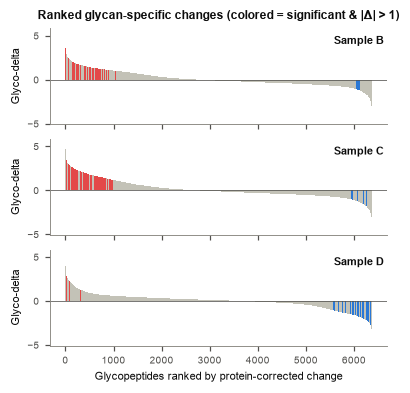

In [22]:
fig, axes = plt.subplots(3, 1, figsize=(W1, 88 * MM), sharex=True, sharey=True)
for ax, s in zip(axes, OTHERS):
    sub = DE[DE.Sample == s].dropna(subset=["glyco_delta"]).sort_values("glyco_delta", ascending=False)
    col = np.where(sub.decoupled & (sub.glyco_delta > 0), UP,
                   np.where(sub.decoupled & (sub.glyco_delta < 0), DOWN, NS))
    ax.bar(np.arange(len(sub)), sub.glyco_delta, width=1.0, color=col, lw=0)
    ax.axhline(0, color=INK2, lw=0.5)
    ax.text(0.99, 0.92, s, transform=ax.transAxes, ha="right", va="top", fontweight="bold")
    ax.set_ylabel("Glyco-delta")
axes[-1].set_xlabel("Glycopeptides ranked by protein-corrected change")
axes[0].set_title("Ranked glycan-specific changes (colored = significant & |Δ| > 1)")
save(fig, "20_ranked_glyco_delta_waterfall")

## 21 Composition shift maps

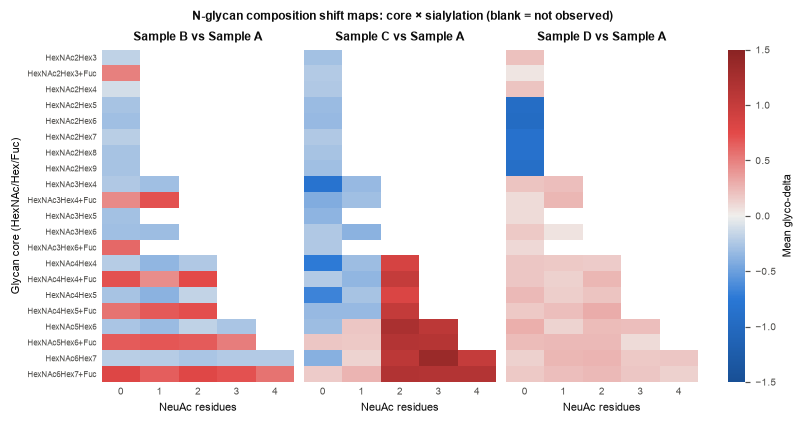

In [23]:
DE["Core"] = "HexNAc" + DE.HexNAc.astype(str) + "Hex" + DE.Hex.astype(str) +     np.where(DE.Fuc > 0, "+Fuc", "")
cores = (DE[DE.Type == "N"].drop_duplicates("Core").sort_values(["HexNAc", "Hex", "Fuc"]).Core.tolist())
sa_r = range(0, 5)
fig, axes = plt.subplots(1, 3, figsize=(W2, 95 * MM), sharey=True)
for ax, s in zip(axes, OTHERS):
    sub = DE[(DE.Sample == s) & (DE.Type == "N")]
    grid = sub.groupby(["Core", "NeuAc"]).glyco_delta.mean().unstack().reindex(index=cores, columns=sa_r)
    im = ax.imshow(grid.values, cmap=DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_xticks(range(len(sa_r)), list(sa_r))
    ax.set_yticks(range(len(cores)), cores, fontsize=5.5)
    ax.set_xlabel("NeuAc residues")
    ax.set_title(f"{s} vs Sample A")
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(length=0)
axes[0].set_ylabel("Glycan core (HexNAc/Hex/Fuc)")
cb = fig.colorbar(im, ax=axes, fraction=0.03)
cb.set_label("Mean glyco-delta")
cb.outline.set_visible(False)
fig.suptitle("N-glycan composition shift maps: core × sialylation (blank = not observed)", fontweight="bold",
             fontsize=8)
save(fig, "21_composition_shift_maps")

## 22 Glycan-class donuts

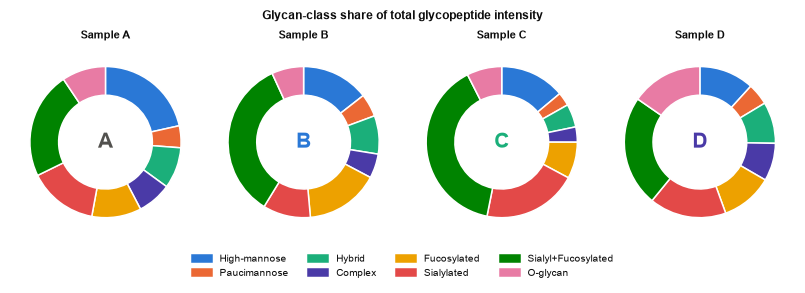

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(W2, 58 * MM))
for ax, s in zip(axes, SAMPLES):
    v = comp[s].reindex(CLASSES).fillna(0)
    ax.pie(v.values, colors=[CLASS_COLORS[c] for c in CLASSES], startangle=90, counterclock=False,
           wedgeprops=dict(width=0.38, edgecolor="white", linewidth=1))
    ax.text(0, 0, s[-1], ha="center", va="center", fontsize=14, fontweight="bold", color=SCOL[s])
    ax.set_title(s, fontsize=7)
fig.legend([Patch(color=CLASS_COLORS[c]) for c in CLASSES], CLASSES, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Glycan-class share of total glycopeptide intensity", fontweight="bold", fontsize=8)
save(fig, "22_glycan_class_donuts")

## 23 Site microheterogeneity (Shannon entropy)

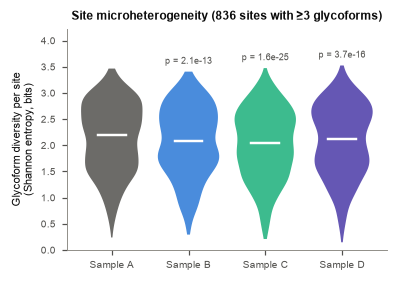

In [25]:
multi = site_n[site_n >= 3].index
ent = {}
for s in SAMPLES:
    m = LIN.loc[GP.Site.isin(multi), DESIGN == s].mean(axis=1)
    p_ = m / m.groupby(GP.loc[m.index, "Site"]).transform("sum")
    ent[s] = (-(p_ * np.log2(p_)).groupby(GP.loc[m.index, "Site"]).sum()).values
fig, ax = plt.subplots(figsize=(W1, 62 * MM))
vp = ax.violinplot([ent[s] for s in SAMPLES], showextrema=False, widths=0.8)
for body, s in zip(vp["bodies"], SAMPLES):
    body.set(facecolor=SCOL[s], edgecolor="none", alpha=0.85)
for i, s in enumerate(SAMPLES, start=1):
    md = np.median(ent[s])
    ax.plot([i - 0.18, i + 0.18], [md, md], color="white", lw=1.6)
    if s != SAMPLES[0]:
        p = stats.wilcoxon(ent[s], ent[SAMPLES[0]]).pvalue
        ax.text(i, max(ent[s]) + 0.15, f"p = {p:.1e}", ha="center", fontsize=6, color=INK2)
ax.set_xticks(range(1, len(SAMPLES) + 1), SAMPLES)
ax.set_ylabel("Glycoform diversity per site\n(Shannon entropy, bits)")
ax.set_ylim(0, max(max(v) for v in ent.values()) + 0.7)
ax.set_title(f"Site microheterogeneity ({len(multi)} sites with ≥3 glycoforms)")
save(fig, "23_site_microheterogeneity_entropy")

## 24 Sialic-acid count distribution

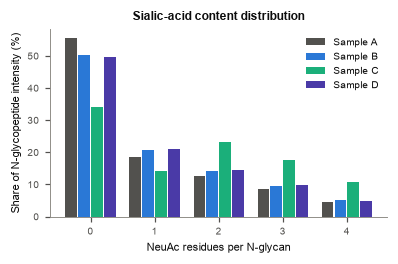

In [26]:
nsa = sample_mean_share(GP.Type == "N", by="NeuAc")
fig, ax = plt.subplots(figsize=(W1, 58 * MM))
w = 0.8 / len(SAMPLES)
for i, s in enumerate(SAMPLES):
    ax.bar(nsa.index + (i - (len(SAMPLES) - 1) / 2) * w, nsa[s], width=w * 0.92, color=SCOL[s], label=s)
ax.set_xticks(nsa.index)
ax.set_xlabel("NeuAc residues per N-glycan")
ax.set_ylabel("Share of N-glycopeptide intensity (%)")
ax.set_title("Sialic-acid content distribution")
ax.legend(loc="upper right")
save(fig, "24_sialic_acid_distribution")

## 25 Top changed glycosites (protein-corrected)

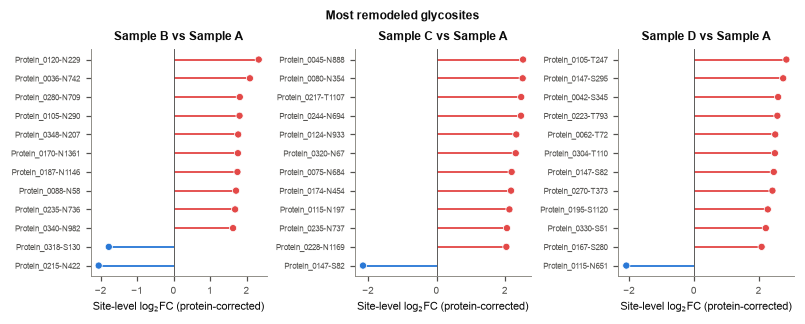

In [27]:
site_fc = {}
for s in OTHERS:
    num = LIN.loc[:, DESIGN == s].mean(axis=1).groupby(GP.Site).sum()
    den = LIN.loc[:, DESIGN == SAMPLES[0]].mean(axis=1).groupby(GP.Site).sum()
    sfc = np.log2(num / den)
    prot = DEP[DEP.Sample == s].set_index("Protein").protein_log2FC
    site_fc[s] = sfc - SITES.loc[sfc.index, "Protein"].map(prot).values
fig, axes = plt.subplots(1, 3, figsize=(W2, 72 * MM))
for ax, s in zip(axes, OTHERS):
    v = site_fc[s].dropna()
    v = v.loc[v.abs().sort_values().index[-12:]].sort_values()
    col = [UP if x > 0 else DOWN for x in v]
    ax.hlines(range(len(v)), 0, v.values, color=col, lw=1.2)
    ax.scatter(v.values, range(len(v)), c=col, s=22, zorder=3, edgecolors="white", lw=0.5)
    ax.axvline(0, color=INK2, lw=0.6)
    ax.set_yticks(range(len(v)), v.index, fontsize=5.5)
    ax.set_xlabel("Site-level log$_2$FC (protein-corrected)")
    ax.set_title(f"{s} vs Sample A")
fig.suptitle("Most remodeled glycosites", fontweight="bold", fontsize=8)
save(fig, "25_top_changed_glycosites")

## 26 Glycoprotein site maps

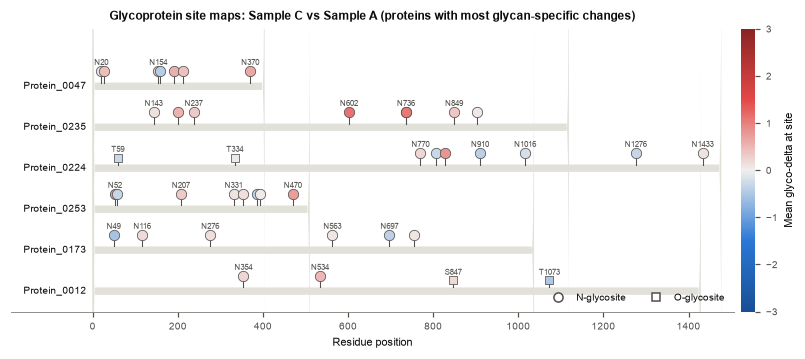

In [28]:
s_map = OTHERS[1]
nsig = DE[(DE.Sample == s_map) & DE.decoupled].groupby("Protein").size().sort_values()
prots = nsig.index[-6:][::-1]
fig, ax = plt.subplots(figsize=(W2, 80 * MM))
sd = DE[DE.Sample == s_map].groupby("Site").glyco_delta.mean()
norm_ = mpl.colors.TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)
maxlen = SITES[SITES.Protein.isin(prots)].Length.max()
for i, p in enumerate(prots):
    y = len(prots) - 1 - i
    L_ = SITES[SITES.Protein == p].Length.iloc[0]
    ax.add_patch(mpl.patches.FancyBboxPatch((0, y - 0.09), L_, 0.18, boxstyle="round,pad=0,rounding_size=6",
                                            color=GRID, lw=0))
    ps = SITES[(SITES.Protein == p) & SITES.index.isin(sd.index)].sort_values("Position")
    last_lab = -1e9
    for site, r in ps.iterrows():
        stem = 0.38 if r.Type == "N" else 0.26
        ax.plot([r.Position, r.Position], [y + 0.09, y + stem], color=INK2, lw=0.7)
        ax.scatter(r.Position, y + stem, s=46 if r.Type == "N" else 30, marker="o" if r.Type == "N" else "s",
                   c=[DIVERGING(norm_(sd[site]))], edgecolors=INK2, lw=0.5, zorder=3)
        if r.Position - last_lab > maxlen * 0.045:      # skip labels that would collide
            ax.text(r.Position, y + stem + 0.1, site.split("-")[1], ha="center", va="bottom",
                    fontsize=5, color=INK2)
            last_lab = r.Position
    ax.text(-maxlen * 0.01, y, p, ha="right", va="center", fontsize=6.5)
ax.set_xlim(-maxlen * 0.13, maxlen * 1.02)
ax.set_ylim(-0.5, len(prots) - 0.1 + 0.5)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xlabel("Residue position")
sm = mpl.cm.ScalarMappable(norm=norm_, cmap=DIVERGING)
cb = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.01)
cb.set_label("Mean glyco-delta at site")
cb.outline.set_visible(False)
ax.legend([Line2D([], [], ls="", marker="o", mfc="white", mec=INK2, ms=6),
           Line2D([], [], ls="", marker="s", mfc="white", mec=INK2, ms=5)],
          ["N-glycosite", "O-glycosite"], loc="lower right", ncol=2)
ax.set_title(f"Glycoprotein site maps: {s_map} vs Sample A (proteins with most glycan-specific changes)")
save(fig, "26_glycoprotein_site_maps")

## Export: multi-page PDF and anonymized tables

In [29]:
if SAVE_FILES:
    with PdfPages(FIG_DIR / "ALL_FIGURES_python.pdf") as pdf:
        for _, f in FIGURES:
            pdf.savefig(f)
            plt.close(f)
    GP_ALL.to_csv(DATA_DIR / "simulated_glycopeptide_annotation.csv", index_label="GP")
    GRAW.round(4).to_csv(DATA_DIR / "simulated_glycopeptide_log2_intensities.csv", index_label="GP")
    PRAW.round(4).to_csv(DATA_DIR / "simulated_protein_log2_intensities.csv", index_label="Protein")
    DE.to_csv(DATA_DIR / "differential_glycosylation_results.csv", index=False)
    TRAITS.round(4).to_csv(DATA_DIR / "derived_glycan_traits.csv", index_label="Trait")
    print(f"\n{len(FIGURES)} figures saved to {FIG_DIR}\nTables saved to {DATA_DIR}")
else:
    print("Notebook mode: figures displayed inline (run the .py script to write files).")

Notebook mode: figures displayed inline (run the .py script to write files).
